![alt text](../../pythonexposed-high-resolution-logo-black.jpg "Optionele titel")

### Meer Plottypes

Je kunt hier een galerij zien van alle verschillende grafieken die mogelijk zijn met Matplotlib:
https://matplotlib.org/gallery/index.html

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

mpl.style.use('seaborn-v0_8-pastel')
plt.rcParams['figure.figsize'] = [12, 8]

Laten we eerst een gegevensset laden:

In [3]:
df = pd.read_csv('populations.csv')
df[:5]

,Geographic Area,"July 1, 2001 Estimate","July 1, 2000 Estimate","April 1, 2000 Population Estimates Base"
0,United States,284796887,282124631,281421906
1,Alabama,4464356,4451493,4447100
2,Alaska,634892,627601,626932
3,Arizona,5307331,5165274,5130632
4,Arkansas,2692090,2678030,2673400


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column                                   Non-Null Count  Dtype 
---  ------                                   --------------  ----- 
 0   Geographic Area                          52 non-null     object
 1   July 1, 2001 Estimate                    52 non-null     int64 
 2   July 1, 2000 Estimate                    52 non-null     int64 
 3   April 1, 2000 Population Estimates Base  52 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 1.8+ KB


Het eerste wat we zullen doen is de eerste rij laten vallen die het totaal voor alle staten bevat, aangezien we de individuele staten apart willen plotten:

In [5]:
data = df.drop(index=0)
data[:5]

,Geographic Area,"July 1, 2001 Estimate","July 1, 2000 Estimate","April 1, 2000 Population Estimates Base"
1,Alabama,4464356,4451493,4447100
2,Alaska,634892,627601,626932
3,Arizona,5307331,5165274,5130632
4,Arkansas,2692090,2678030,2673400
5,California,34501130,34000446,33871648


We gaan de gegevens van de 'July 1, 2001 Estimate' plotten. Ik wil dat mijn plot van de grootste naar de kleinste bevolking gaat, dus ik ga de gegevens sorteren op die kolom:

In [6]:
data.sort_values('July 1, 2001 Estimate')[:5]

,Geographic Area,"July 1, 2001 Estimate","July 1, 2000 Estimate","April 1, 2000 Population Estimates Base"
51,Wyoming,494423,494001,493782
9,District of Columbia,571822,571066,572059
46,Vermont,613090,609709,608827
35,North Dakota,634448,640919,642200
2,Alaska,634892,627601,626932


Dit sorteert in oplopende volgorde, dus we moeten de sorteerrichting omkeren:

In [7]:
data = data.sort_values('July 1, 2001 Estimate', ascending=False)
data[:5]

,Geographic Area,"July 1, 2001 Estimate","July 1, 2000 Estimate","April 1, 2000 Population Estimates Base"
5,California,34501130,34000446,33871648
44,Texas,21325018,20946503,20851820
33,New York,19011378,18989332,18976457
10,Florida,16396515,16054328,15982378
14,Illinois,12482301,12435970,12419293


Nu kunnen we doorgaan en deze waarden plotten - we zullen beginnen met de lijngrafiek die we eerder hebben gezien:

Text(0, 0.5, 'population')

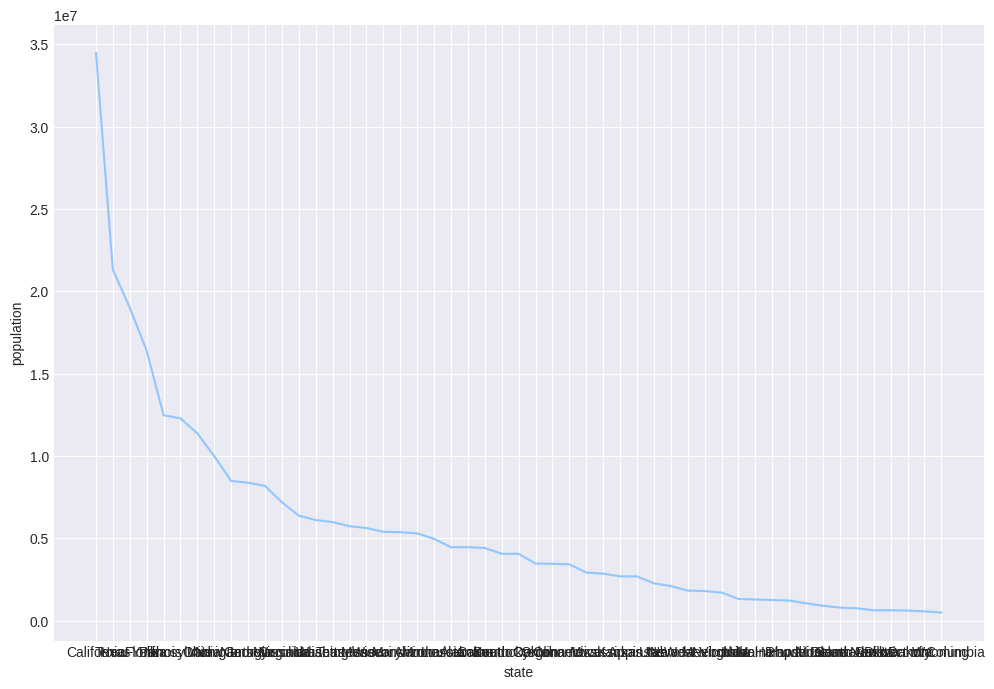

In [8]:
fig, ax = plt.subplots()
ax.plot(
    data['Geographic Area'].values,
    data['July 1, 2001 Estimate'].values,
    label='population'
)
ax.set_xlabel('state')
ax.set_ylabel('population')

We kunnen de x-as labels niet zien omdat er te veel zijn en ze overlappen.
Om dit op te lossen zouden we een subset van de data kunnen plotten, maar we zouden ook gewoon de labels kunnen roteren:

Text(0, 0.5, 'population')

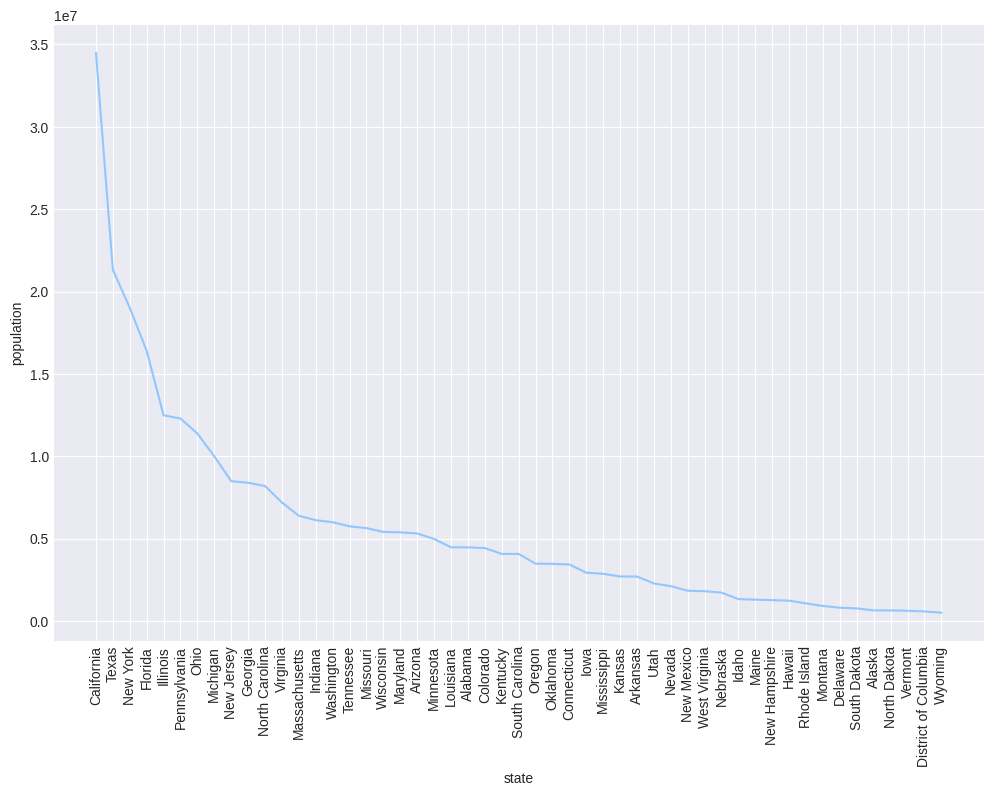

In [9]:
fig, ax = plt.subplots()
ax.plot(
    data['Geographic Area'].values,
    data['July 1, 2001 Estimate'].values,
    label='population'
)
plt.xticks(rotation=90)
ax.set_xlabel('state')
ax.set_ylabel('population')

Voor dit soort gegevensset zijn balken beter geschikt dan een lijngrafiek:

Text(0, 0.5, 'population')

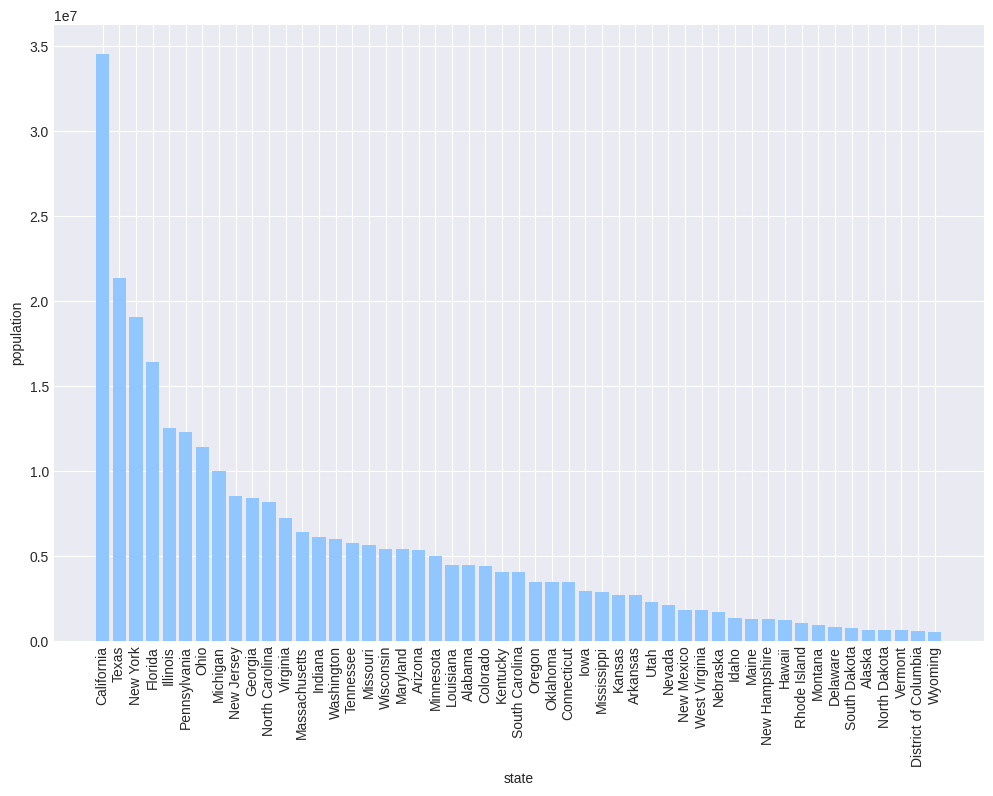

In [10]:
fig, ax = plt.subplots()
ax.bar(
    data['Geographic Area'].values,
    data['July 1, 2001 Estimate'].values,
    label='population'
)
plt.xticks(rotation=90)
ax.set_xlabel('state')
ax.set_ylabel('population')

Let op de eenheden op de y-as - ze zijn in veelvouden van `1e7` - ik zou liever zelf de controle daarover hebben - laten we dus de gegevens voor die specifieke kolom bekijken en een geschikte vermenigvuldigingsfactor kiezen:

In [10]:
data['July 1, 2001 Estimate'].describe()

count    5.100000e+01
mean     5.584253e+06
std      6.263147e+06
min      4.944230e+05
25%      1.517120e+06
50%      4.063011e+06
75%      6.247024e+06
max      3.450113e+07
Name: July 1, 2001 Estimate, dtype: float64

Zoals we kunnen zien, hebben we gegevens variërend van `10^5` (`100_000`) tot `10^7` (`10_000_000`).

Op basis van de kwartielen, bevindt het merendeel van de gegevens zich in de miljoenen, dus ik ga de gegevens opnieuw schalen en dat in plaats daarvan plotten:

Text(0, 0.5, 'population (millions)')

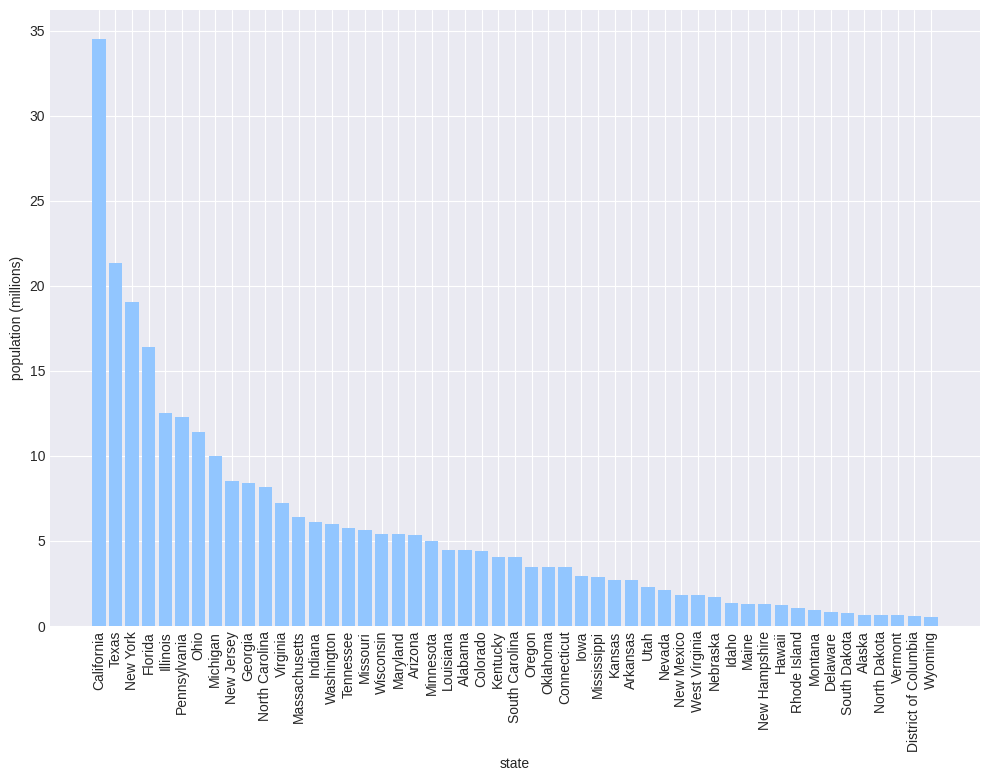

In [11]:
fig, ax = plt.subplots()
ax.bar(
    data['Geographic Area'].values,
    (data['July 1, 2001 Estimate']/1_000_000).values,
    label='population'
)
plt.xticks(rotation=90)
ax.set_xlabel('state')
ax.set_ylabel('population (millions)')

#### Histogrammen

Laten we eens kijken hoe we histogrammen kunnen plotten. We kunnen dit onder andere doen door eerst een histogram te genereren met behulp van NumPy en vervolgens een staafdiagram te gebruiken.

Laten we eerst wat gegevens genereren:

In [12]:
import random

random.seed(0)
data_1 = [random.gauss(0, 1) for _ in range(1_000_000)]

Of we kunnen gewoon de NumPy-module gebruiken:

In [13]:
np.random.seed(0)
data_2 = np.random.normal(0, 1, size=1_000_000)

Laten we NumPy gebruiken om een frequentieverdeling te genereren:

In [14]:
freq_1, bins_1 = np.histogram(data_1, bins=50)
freq_2, bins_2 = np.histogram(data_2, bins=50)

Onthoud dat de output van `np.histogram` een **tuple** is die de frequenties en de bins bevat.

Laten we nu elk ervan plotten en bekijken hoe de verdeling eruitziet, met behulp van een staafdiagram:

Text(0.5, 1.0, 'NumPy Generated')

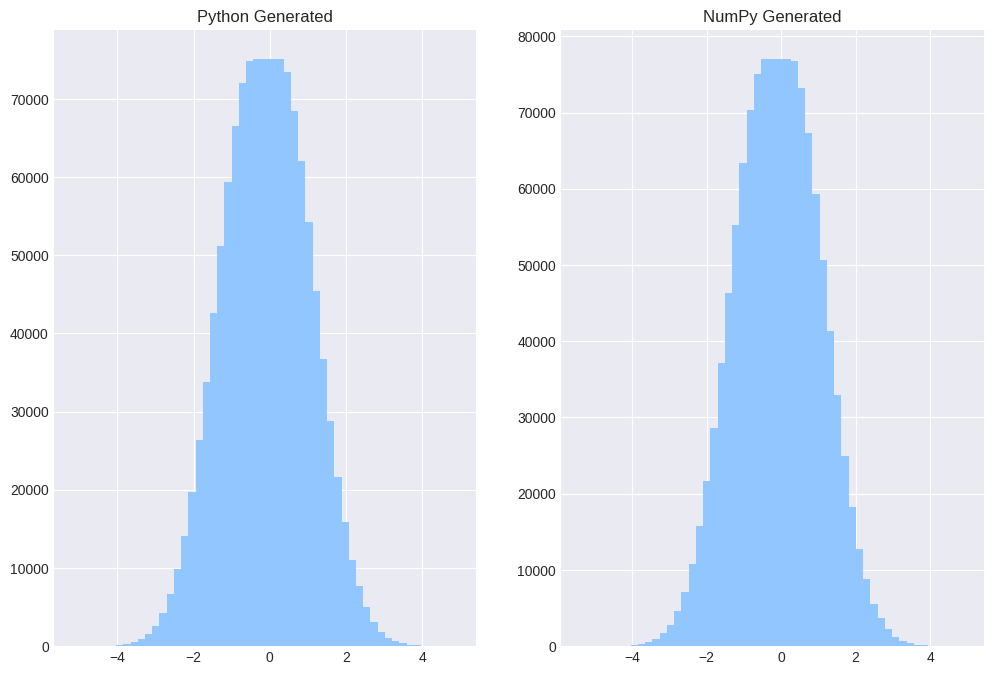

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2) # 1 rij, 2 kolommen - 2 axes
ax1.bar(
    bins_1[:-1], 
    freq_1
)
ax1.set_title('Python Generated')

ax2.bar(
    bins_2[:-1], 
    freq_2
)
ax2.set_title('NumPy Generated')

We zouden ook een spreidingsdiagram (scatter plot) kunnen gebruiken:

Text(0.5, 1.0, 'NumPy Generated')

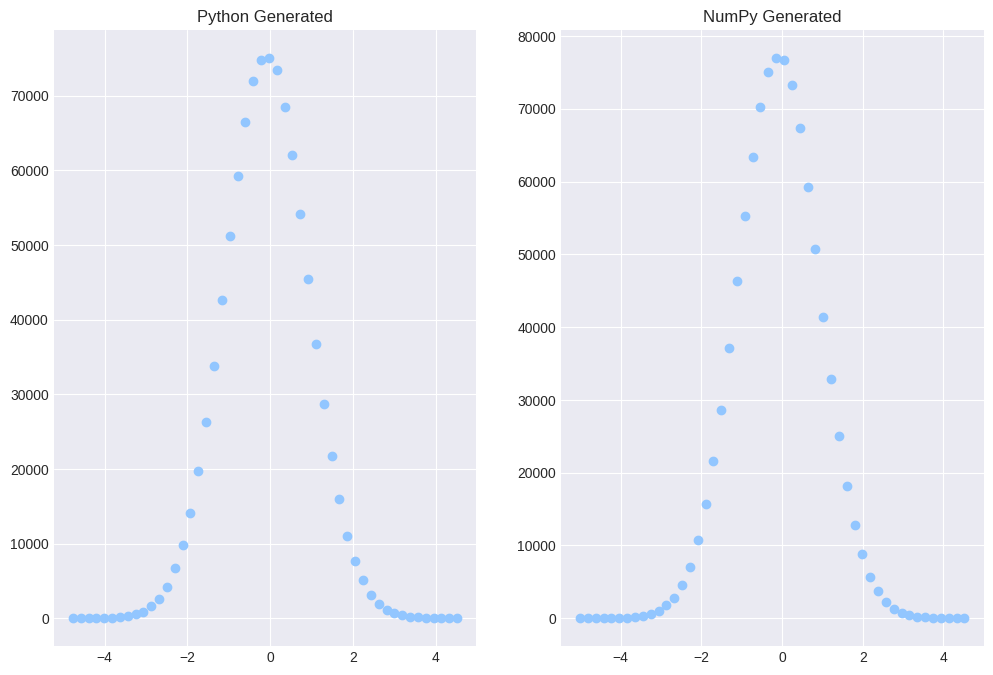

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.scatter(
    bins_1[:-1], 
    freq_1
)
ax1.set_title('Python Generated')

ax2.scatter(
    bins_2[:-1], 
    freq_2
)
ax2.set_title('NumPy Generated')

Of een lijngrafiek:

Text(0.5, 1.0, 'NumPy Generated')

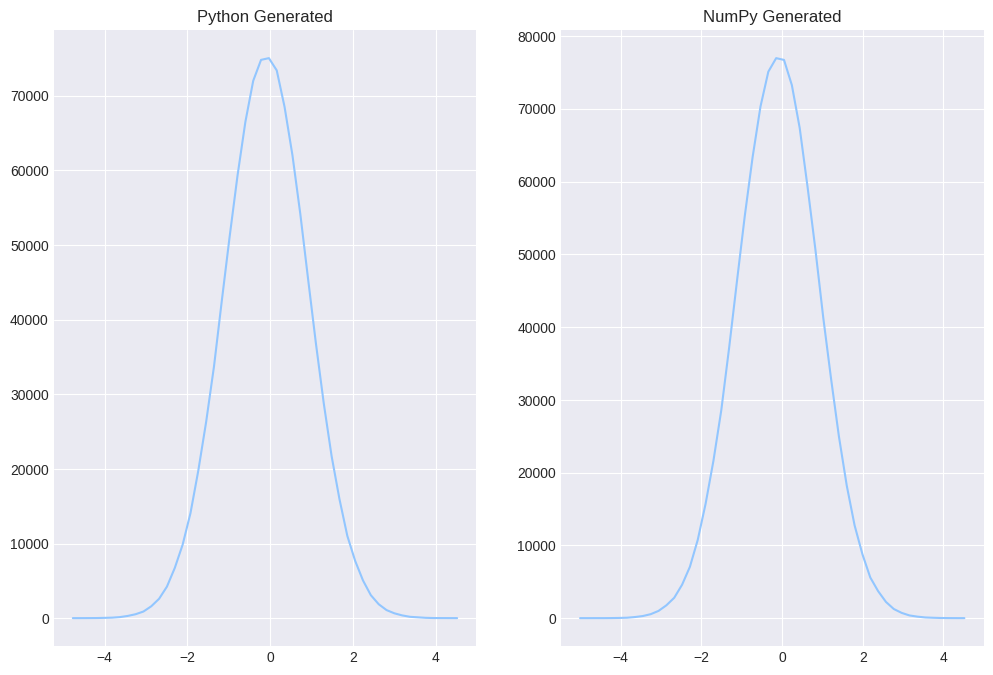

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.plot(
    bins_1[:-1], 
    freq_1
)
ax1.set_title('Python Generated')

ax2.plot(
    bins_2[:-1], 
    freq_2
)
ax2.set_title('NumPy Generated')

We gaan nu enkele verticale lijnen op de grafiek tekenen om de 10e, 50e en 90e percentielen aan te geven:

In [21]:
percentiles_1 = [np.percentile(data_1, p) for p in (10, 50, 90)] 
percentiles_2 = [np.percentile(data_2, p) for p in (10, 50, 90)] 

In [22]:
percentiles_1, percentiles_2

([-1.2812666182390375, 0.0009163848983922004, 1.2824949027126349],
 [-1.2796066647113746, 0.002387730826572747, 1.282046718132256])

We kunnen de `axvline`-methode gebruiken om dat te doen:

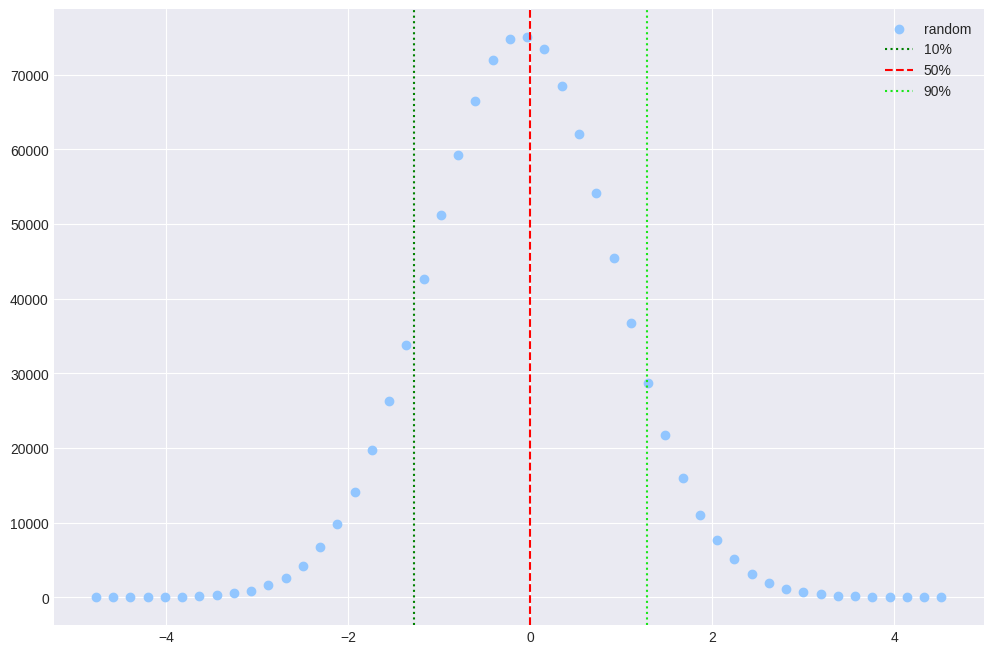

In [23]:
fig, ax = plt.subplots()
ax.scatter(
    bins_1[:-1], 
    freq_1,
    label='random'
)
ax.axvline(percentiles_1[0], linestyle=':', color='green', label='10%')
ax.axvline(percentiles_1[1], linestyle='--', color='red', label='50%')
ax.axvline(
    percentiles_1[2], 
    linestyle=':', 
    color=mpl.colors.to_rgba((0.1, 0.9, 0.1)), label='90%')
ax.legend()

Net zoals NumPy een histogramfunctie heeft, heeft Matplotlib ook zo'n functie die we direct kunnen gebruiken, in plaats van eerst NumPy te gebruiken.

(array([3.0000e+00, 2.0000e+00, 5.0000e+00, 3.0000e+00, 1.2000e+01,
        3.0000e+01, 6.0000e+01, 1.5400e+02, 2.9100e+02, 5.4600e+02,
        9.9500e+02, 1.7630e+03, 2.7990e+03, 4.5850e+03, 7.0550e+03,
        1.0752e+04, 1.5709e+04, 2.1621e+04, 2.8564e+04, 3.7135e+04,
        4.6301e+04, 5.5297e+04, 6.3388e+04, 7.0308e+04, 7.5101e+04,
        7.6963e+04, 7.6717e+04, 7.3256e+04, 6.7368e+04, 5.9287e+04,
        5.0686e+04, 4.1335e+04, 3.2899e+04, 2.4980e+04, 1.8217e+04,
        1.2751e+04, 8.7780e+03, 5.5890e+03, 3.7130e+03, 2.2290e+03,
        1.2550e+03, 7.2500e+02, 3.7200e+02, 2.1000e+02, 9.8000e+01,
        5.4000e+01, 2.2000e+01, 1.0000e+01, 4.0000e+00, 3.0000e+00]),
 array([-5.00229865, -4.80791943, -4.61354022, -4.419161  , -4.22478179,
        -4.03040257, -3.83602335, -3.64164414, -3.44726492, -3.25288571,
        -3.05850649, -2.86412727, -2.66974806, -2.47536884, -2.28098963,
        -2.08661041, -1.89223119, -1.69785198, -1.50347276, -1.30909355,
        -1.11471433, -0.92

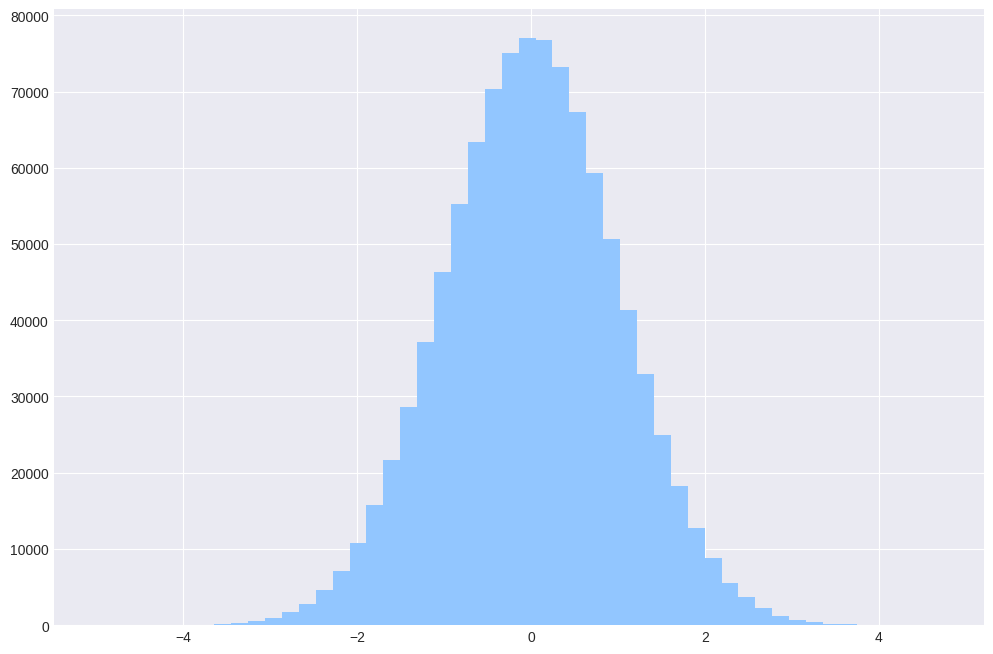

In [24]:
fig, ax = plt.subplots()
ax.hist(data_2, bins=50)

Als we de uitvoer van de hist-functie (behalve de grafiek) niet willen zien, kunnen we deze eenvoudig toewijzen aan een variabele:

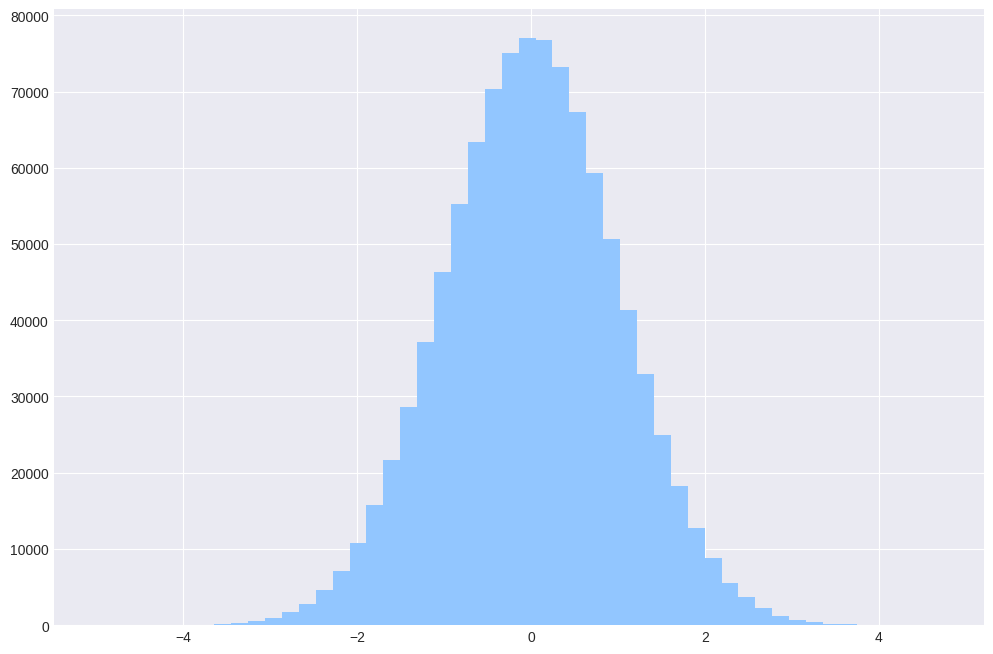

In [25]:
fig, ax = plt.subplots()
_ = ax.hist(data_2, bins=50)

#### 2D Histogram

In [9]:
# Dataset: adult.csv (inkomen van volwassenen)

incomes = pd.read_csv('../06 - Exercises/adult.csv')

incomes.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


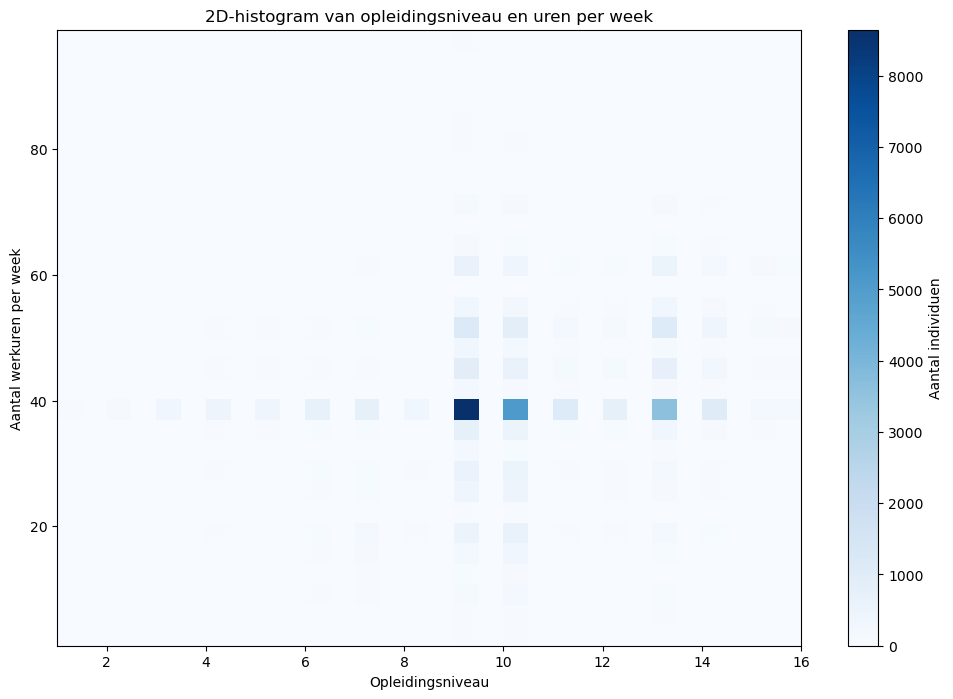

In [12]:
# Maak een 2D-histogram
plt.hist2d(incomes['educational-num'], incomes['hours-per-week'], bins=[30, 30], cmap='Blues')

# # Voeg een kleurstaaf toe om de waarden van de bins te tonen
plt.colorbar(label='Aantal individuen')

# Labels en titel
plt.xlabel('Opleidingsniveau')
plt.ylabel('Aantal werkuren per week')
plt.title('2D-histogram van opleidingsniveau en uren per week')

# # Toon de grafiek
plt.show()

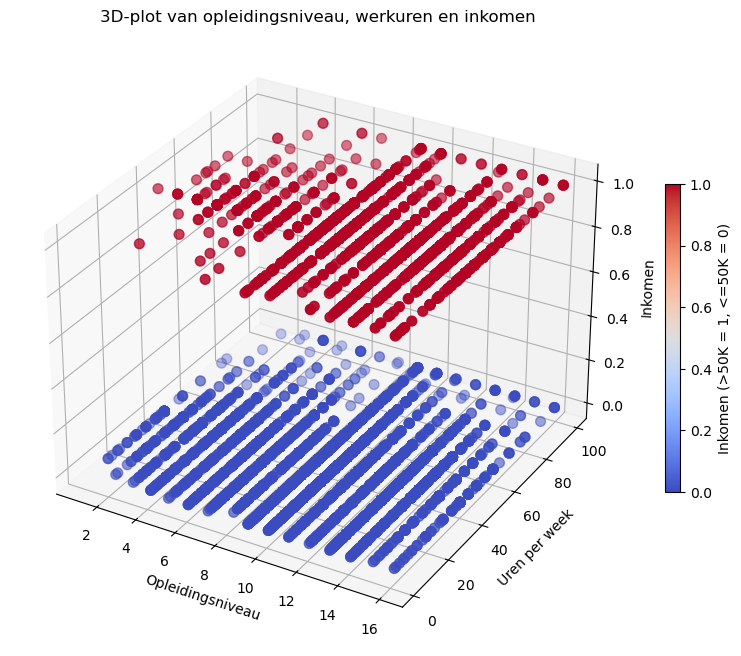

In [14]:
# Maak een 3D-histogram
from mpl_toolkits.mplot3d import Axes3D

# Voorwaarden instellen
education = incomes['educational-num']
hours_per_week = incomes['hours-per-week']
income = incomes['income'].apply(lambda x: 1 if x == '>50K' else 0)  # Inkomenscategorie

# Maak een 3D figuur
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 3D scatter plot maken
sc = ax.scatter(education, hours_per_week, income, c=income, cmap='coolwarm', s=50)

# Voeg kleurstaaf toe voor de inkomenscategorieën
cbar = plt.colorbar(sc, ax=ax, shrink=0.5)
cbar.set_label('Inkomen (>50K = 1, <=50K = 0)')

# Labels en titel
ax.set_xlabel('Opleidingsniveau')
ax.set_ylabel('Uren per week')
ax.set_zlabel('Inkomen')
ax.set_title('3D-plot van opleidingsniveau, werkuren en inkomen')

# Toon de grafiek
plt.show()
